# Taller: Árboles de Decisión


### Aprendizaje Supervisado — CART, Gini y `DecisionTreeClassifier`




**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 13-10-2026

> **Cómo usar este material:** este taller es una **guía de referencia en HTML**, no un notebook interactivo.
> Reproduce cada celda de código en tu propio Google Colab o Jupyter Notebook, en el mismo orden en que
> aparece: cada bloque usa los objetos creados en el anterior. Necesitas los archivos
> `aprobacion_credito_ecuador.csv` (Partes A y C) y `triaje_hospitalario_ecuador.csv` (Parte B).


## Objetivos del taller



Al finalizar este taller el estudiante será capaz de:

1. Entrenar un `DecisionTreeClassifier` y leer el árbol con `plot_tree()` y `export_text()`.
2. Evaluar el árbol y detectar el sobreajuste comparando el accuracy en entrenamiento y en prueba.
3. Controlar la complejidad del árbol con `max_depth` y `min_samples_leaf`, eligiéndolos con `GridSearchCV`.
4. Reentrenar el modelo final con el 100% de los datos, exportarlo con `joblib` y usarlo con datos nuevos.


## Datasets



**`aprobacion_credito_ecuador.csv`** — 900 solicitudes de crédito (dataset sintético, sin valores nulos). Partes A y C.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `edad` | Numérica | Edad del solicitante (22 a 65 años) |
| `ingresos_mensuales` | Numérica | Ingresos mensuales en USD |
| `meses_empleo` | Numérica | Meses en el empleo actual |
| `deuda_actual` | Numérica | Deuda total actual en USD |
| `num_creditos_previos` | Numérica | Número de créditos anteriores (0 a 8) |
| `riesgo_crediticio` | Objetivo (y) | 1 = riesgoso · 0 = no riesgoso |

**`triaje_hospitalario_ecuador.csv`** — 1 200 pacientes de un centro de salud (dataset sintético, sin valores nulos). Parte B.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `edad` | Numérica | Edad del paciente (años) |
| `frecuencia_cardiaca` | Numérica | Pulsaciones por minuto |
| `presion_sistolica` | Numérica | Presión arterial sistólica (mmHg) |
| `temperatura` | Numérica | Temperatura corporal (°C) |
| `saturacion_o2` | Numérica | Saturación de oxígeno en sangre (%) |
| `motivo_consulta` | Categórica (texto) | cefalea, trauma, fiebre, dolor_pecho, … |
| `prioridad_urgente` | Objetivo (y) | 1 = urgente · 0 = no urgente |


## Estructura del taller



| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga y exploración (crédito) |
| A2 | Guiado | X, y y división train/test |
| A3 | Guiado | Primer árbol con `max_depth=3` |
| A4 | Guiado | Visualizar el árbol y leer sus reglas |
| A5 | Guiado | Evaluación en prueba |
| A6 | Guiado | Sobreajuste: árbol sin límite y curva de profundidad |
| A7 | Guiado | Importancia de variables |
| A8 | Guiado | `GridSearchCV` aplicado al árbol |
| B1 | Autónomo | Triaje: datos, codificación y división |
| B2 | Autónomo | Triaje: primer árbol e interpretación |
| B3 | Autónomo | Triaje: sobreajuste y `GridSearchCV` con `scoring='recall'` |
| C | Guiado | Entrenamiento final (100%), exportación y uso con datos nuevos |


## Rúbrica de evaluación (10 puntos)



| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A8 y C (guiados) | Reproducidos completos y sin errores en tu notebook | 1.5 |
| B1 — código | Variable categórica codificada, X/y correctos y división con `stratify` | 1.5 |
| B2 — código | Árbol entrenado, visualizado y evaluado (train y test) | 1.5 |
| B2 — análisis | Respuestas justificadas sobre la raíz y las reglas | 1.5 |
| B3 — código | Comparación de profundidades y `GridSearchCV` con `scoring='recall'` correctos | 2.0 |
| B3 — análisis | Tabla completa y respuestas justificadas | 2.0 |


# Parte A — Laboratorio Guiado: Riesgo Crediticio


## Bloque A1 · Carga y exploración



**Librerías que usamos:** `pandas` (datos) y `matplotlib.pyplot` (gráficos).


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('aprobacion_credito_ecuador.csv')
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print("Valores nulos:", df.isnull().sum().sum())
df.head()


Filas: 900 | Columnas: 6
Valores nulos: 0


,edad,ingresos_mensuales,meses_empleo,deuda_actual,num_creditos_previos,riesgo_crediticio
0,47,3569,52,9821,2,0
1,30,1159,65,11944,6,1
2,56,1185,160,8016,3,1
3,61,2225,203,14778,5,1
4,65,2191,39,7560,2,1


riesgo_crediticio
0    478
1    422
Name: count, dtype: int64


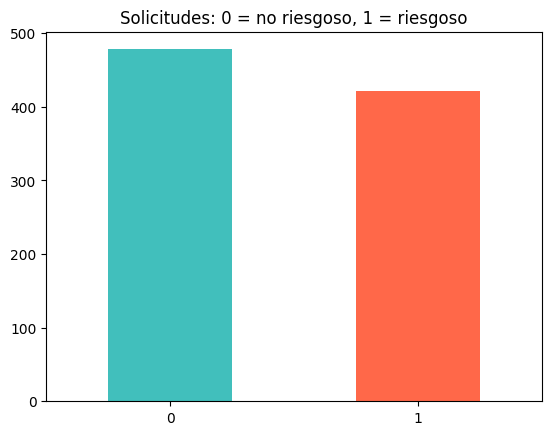

In [11]:
conteo = df['riesgo_crediticio'].value_counts()
print(conteo)

ax = conteo.plot(kind='bar', color=['#41BFBC', '#FF6849'])
ax.set_title('Solicitudes: 0 = no riesgoso, 1 = riesgoso')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.show()


**Observación:** 478 no riesgosos (53%) y 422 riesgosos (47%): las clases están **balanceadas**.
Por eso usaremos **Accuracy** y **F1** para evaluar (ambas con rango 0 a 1 → 1 = deseado).


## Bloque A2 · X, y y división train/test



**Librería:** `train_test_split`.

* `X` = las 5 variables predictoras · `y` = la columna `riesgo_crediticio`.
* `stratify=y` mantiene el 47% de riesgosos tanto en entrenamiento como en prueba.
* `X_test` se reserva para medir el modelo con datos que **no vio** al entrenar.


In [12]:
from sklearn.model_selection import train_test_split

X = df.drop('riesgo_crediticio', axis=1)
y = df['riesgo_crediticio']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entrenamiento: {X_train.shape[0]} filas | % riesgosos: {y_train.mean() * 100:.1f}%")
print(f"Prueba:        {X_test.shape[0]} filas | % riesgosos: {y_test.mean() * 100:.1f}%")


Entrenamiento: 720 filas | % riesgosos: 46.9%
Prueba:        180 filas | % riesgosos: 46.7%


## Bloque A3 · Primer árbol con `max_depth=3`



**Librería:** `DecisionTreeClassifier`.

* `max_depth=3` limita el árbol a 3 niveles de preguntas: es sencillo de leer y tiene poco riesgo de sobreajuste.
* `random_state=42` hace que el resultado sea repetible (desempata divisiones con la misma calidad).
* **No escalamos los datos:** el árbol compara cada variable con un umbral (`deuda_actual <= 5975.5`);
escalar cambia los números pero no el orden de los casos, así que las divisiones serían las mismas.


In [13]:
from sklearn.tree import DecisionTreeClassifier

arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_train, y_train)   # datos sin escalar

print("Profundidad real:", arbol.get_depth())
print("Número de hojas: ", arbol.get_n_leaves())


Profundidad real: 3
Número de hojas:  8


## Bloque A4 · Visualizar el árbol y leer sus reglas



**Librerías:** `plot_tree` (dibujo) y `export_text` (reglas en texto).

Cada nodo de `plot_tree` muestra:

* la **pregunta** (variable `<=` umbral); a la izquierda va la respuesta **Sí (True)**, a la derecha **No (False)**;
* `gini`: impureza del nodo (0 = puro);
* `samples`: cuántas solicitudes de entrenamiento llegaron al nodo;
* `value`: cuántas son de cada clase `[no riesgoso, riesgoso]`;
* `class`: la clase mayoritaria (la que predice si fuera hoja).

**Colores:** naranja = No riesgoso, azul = Riesgoso; cuanto más intenso el color, más puro es el nodo.


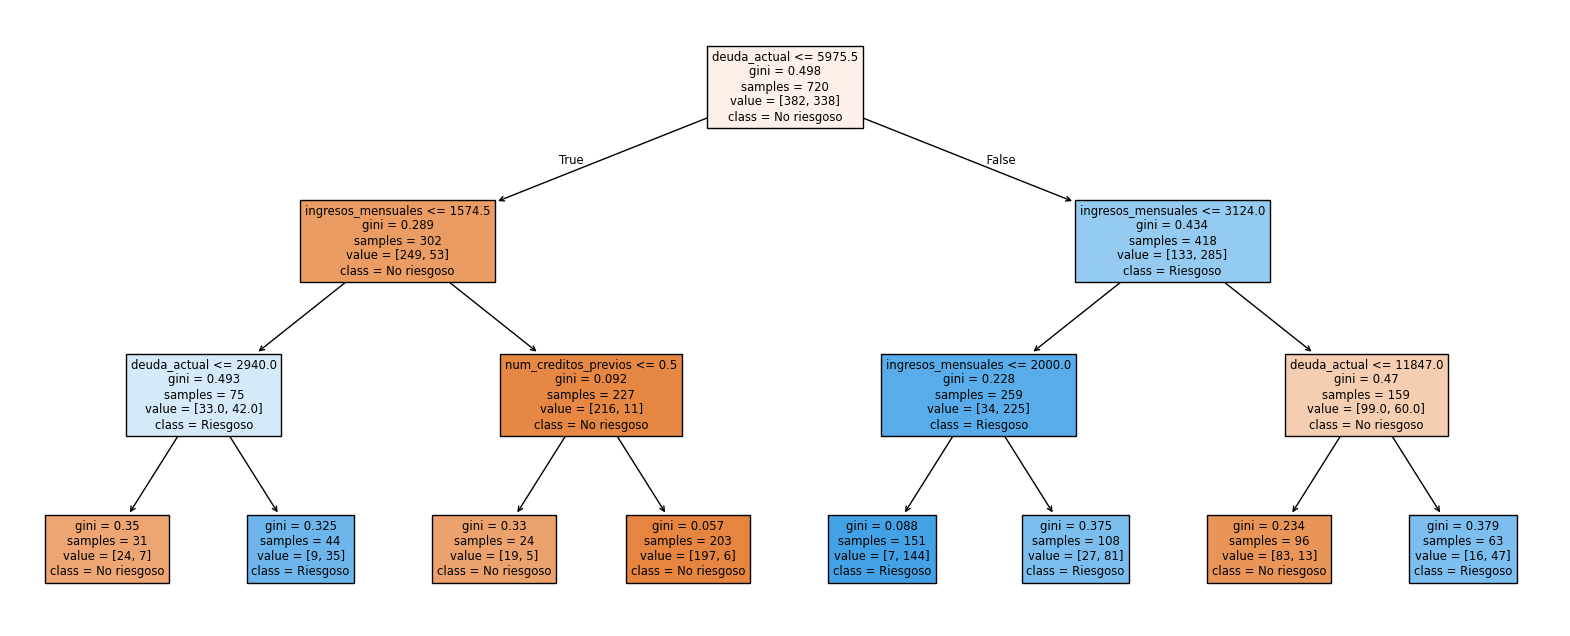

In [14]:
from sklearn.tree import plot_tree, export_text

plt.figure(figsize=(20, 8))
plot_tree(arbol, filled=True,
          feature_names=list(X.columns),
          class_names=['No riesgoso', 'Riesgoso'])
plt.show()


In [15]:
print(export_text(arbol, feature_names=list(X.columns)))


|--- deuda_actual <= 5975.50
|   |--- ingresos_mensuales <= 1574.50
|   |   |--- deuda_actual <= 2940.00
|   |   |   |--- class: 0
|   |   |--- deuda_actual >  2940.00
|   |   |   |--- class: 1
|   |--- ingresos_mensuales >  1574.50
|   |   |--- num_creditos_previos <= 0.50
|   |   |   |--- class: 0
|   |   |--- num_creditos_previos >  0.50
|   |   |   |--- class: 0
|--- deuda_actual >  5975.50
|   |--- ingresos_mensuales <= 3124.00
|   |   |--- ingresos_mensuales <= 2000.00
|   |   |   |--- class: 1
|   |   |--- ingresos_mensuales >  2000.00
|   |   |   |--- class: 1
|   |--- ingresos_mensuales >  3124.00
|   |   |--- deuda_actual <= 11847.00
|   |   |   |--- class: 0
|   |   |--- deuda_actual >  11847.00
|   |   |   |--- class: 1



**Lectura:**

* La raíz pregunta por `deuda_actual <= 5975.5`: es la división con **mayor reducción de Gini**
  (de 0.498 en la raíz a 0.373 ponderado en los hijos, ΔGini = 0.125, como vimos en la teoría).
* En la rama izquierda (deuda baja) la siguiente pregunta es por los ingresos; con ingresos altos casi
  todos son **no riesgosos** (Gini 0.057 en la hoja con 203 solicitudes).
* Cada camino raíz → hoja es una regla **SI … ENTONCES …** que un analista de crédito puede leer.


## Bloque A5 · Evaluación en prueba



**Librerías:** `classification_report` y `ConfusionMatrixDisplay`.


In [16]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred = arbol.predict(X_test)
print(f"Accuracy entrenamiento: {arbol.score(X_train, y_train):.3f}")
print(f"Accuracy prueba:        {arbol.score(X_test, y_test):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=['No riesgoso', 'Riesgoso']))


Accuracy entrenamiento: 0.875
Accuracy prueba:        0.861

              precision    recall  f1-score   support

 No riesgoso       0.89      0.84      0.87        96
    Riesgoso       0.83      0.88      0.86        84

    accuracy                           0.86       180
   macro avg       0.86      0.86      0.86       180
weighted avg       0.86      0.86      0.86       180



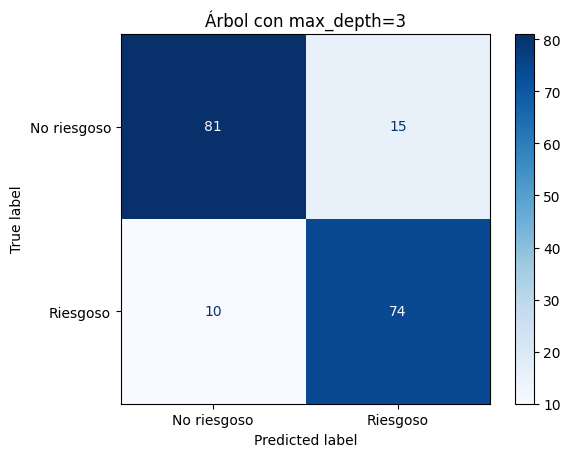

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['No riesgoso', 'Riesgoso'], cmap='Blues')
plt.title('Árbol con max_depth=3')
plt.show()


**Lectura** (rango 0 a 1 → 1 = deseado):

* Accuracy 0.875 en entrenamiento y 0.861 en prueba: la **brecha es pequeña**, el árbol generaliza bien.
* Detecta 74 de los 84 solicitantes riesgosos del conjunto de prueba (Recall = 0.881).


## Bloque A6 · Sobreajuste: árbol sin límite y curva de profundidad



Con los valores por defecto (`max_depth=None`) el árbol crece hasta que **todas** sus hojas son puras.


In [18]:
arbol_libre = DecisionTreeClassifier(random_state=42)   # sin límite
arbol_libre.fit(X_train, y_train)

print("Profundidad:", arbol_libre.get_depth(), "| Hojas:", arbol_libre.get_n_leaves())
print(f"Accuracy entrenamiento: {arbol_libre.score(X_train, y_train):.3f}")
print(f"Accuracy prueba:        {arbol_libre.score(X_test, y_test):.3f}")


Profundidad: 11 | Hojas: 85
Accuracy entrenamiento: 1.000
Accuracy prueba:        0.822


El árbol sin límite acierta el **100%** en entrenamiento pero baja en prueba: memorizó casos particulares
(**sobreajuste**). Veamos cómo cambia el accuracy para profundidades de 1 a 15:


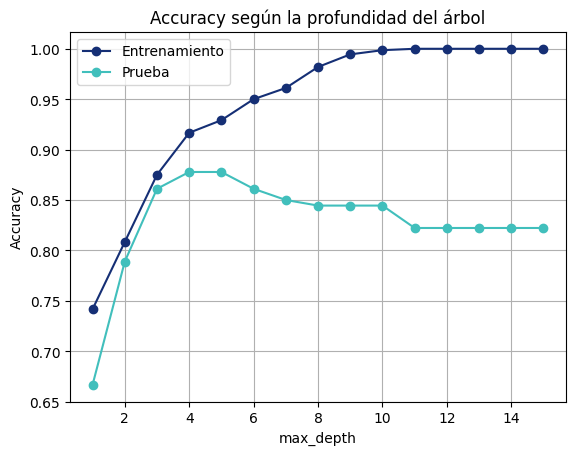

,Entrenamiento,Prueba
max_depth,,
1,0.742,0.667
2,0.808,0.789
3,0.875,0.861
4,0.917,0.878
5,0.929,0.878
6,0.950,0.861
7,0.961,0.850
8,0.982,0.844


In [19]:
filas = []
for d in range(1, 16):
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    filas.append({'max_depth': d,
                  'Entrenamiento': m.score(X_train, y_train),
                  'Prueba': m.score(X_test, y_test)})

curva = pd.DataFrame(filas).set_index('max_depth')
ax = curva.plot(marker='o', color=['#152F75', '#41BFBC'], grid=True)
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy según la profundidad del árbol')
plt.show()

curva.round(3).head(8)


**Lectura de la curva:**

* Con profundidad 1–2 el árbol es demasiado simple (**underfitting**): ambas curvas están bajas.
* Con profundidad 4–5 la prueba alcanza su máximo (≈ 0.878).
* Desde profundidad 6 el entrenamiento sigue subiendo hacia 1.0, pero la prueba **baja**: la brecha
creciente es la señal de **sobreajuste**.


## Bloque A7 · Importancia de variables



`feature_importances_` indica cuánto redujo cada variable la impureza (Gini) en todo el árbol.
Rango 0 a 1; la suma de todas es 1.


deuda_actual            0.609
ingresos_mensuales      0.385
num_creditos_previos    0.006
edad                    0.000
meses_empleo            0.000
dtype: float64


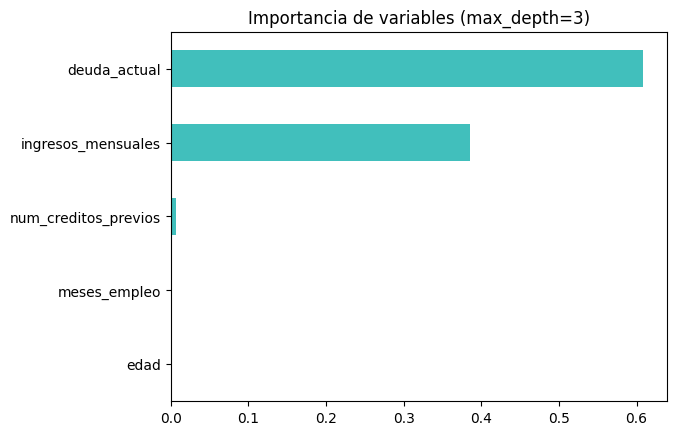

In [20]:
importancia = pd.Series(arbol.feature_importances_, index=X.columns).sort_values()
print(importancia.sort_values(ascending=False).round(3))

ax = importancia.plot(kind='barh', color='#41BFBC')
ax.set_title('Importancia de variables (max_depth=3)')
plt.show()


**Lectura:** `deuda_actual` (0.609) e `ingresos_mensuales` (0.385) explican casi todas las decisiones.
`edad` y `meses_empleo` tienen importancia 0: el árbol de profundidad 3 **no las usó** en ninguna pregunta.


## Bloque A8 · `GridSearchCV` aplicado al árbol



**Librería:** `GridSearchCV` (vista en la clase anterior).

* Como no hay escalador, **no hace falta un `Pipeline`**: los nombres del `param_grid` van directos
  (`'max_depth'`, no `'modelo__max_depth'`).
* 5 valores de `max_depth` × 4 de `min_samples_leaf` = **20 combinaciones**; con `cv=5` son 100 entrenamientos
  (+1 final con todo `X_train`).
* `scoring='f1'`: equilibra Precision y Recall de la clase Riesgoso.


In [21]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

param_grid = {'max_depth': [3, 4, 5, 6, None],
              'min_samples_leaf': [1, 5, 10, 20]}
base = DecisionTreeClassifier(random_state=42)
grid = GridSearchCV(base, param_grid, cv=5, scoring='f1')
grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid.best_params_)
print(f"Mejor F1 promedio en CV: {grid.best_score_:.3f}")


Mejores hiperparámetros: {'max_depth': 5, 'min_samples_leaf': 10}
Mejor F1 promedio en CV: 0.864


In [22]:
y_pred_grid = grid.predict(X_test)
y_pred_libre = arbol_libre.predict(X_test)

comparacion = pd.DataFrame({
    'Modelo': ['Sin límite', 'max_depth=3 (a mano)', 'GridSearchCV'],
    'Accuracy': [accuracy_score(y_test, y_pred_libre), accuracy_score(y_test, y_pred),
                 accuracy_score(y_test, y_pred_grid)],
    'F1': [f1_score(y_test, y_pred_libre), f1_score(y_test, y_pred),
           f1_score(y_test, y_pred_grid)],
})
comparacion.round(3)


,Modelo,Accuracy,F1
0,Sin límite,0.822,0.812
1,max_depth=3 (a mano),0.861,0.855
2,GridSearchCV,0.872,0.862


**Lectura:** `GridSearchCV` eligió `max_depth=5` y `min_samples_leaf=10` (F1 en prueba ≈ 0.862).
La gran mejora es frente al árbol **sin límite** (F1 ≈ 0.812): limitar el crecimiento es lo que más importa.


# Parte B — Práctica Autónoma: Triaje Hospitalario



**Contexto:** un centro de salud quiere priorizar automáticamente a los pacientes que llegan a emergencias
usando `triaje_hospitalario_ecuador.csv`. Objetivo: predecir `prioridad_urgente` (1 = urgente).

**¿Por qué `scoring='recall'` en el Bloque B3?** Un **falso negativo** (no detectar a un paciente urgente)
es mucho más grave que un falso positivo (atender antes a alguien que podía esperar). Recall mide qué
proporción de los urgentes reales detecta el modelo (rango 0 a 1 → 1 = deseado).

En **tu propio notebook**, escribe el código que reemplace cada `# TODO` que ves en esta guía y responde
las preguntas en una celda de texto. Sigue la misma secuencia de la Parte A, con nombres terminados en `_b`.


## Bloque B1 · Datos, codificación y división



La columna `motivo_consulta` es **texto** y scikit-learn solo acepta números. Usa `pd.get_dummies()`,
que crea una columna 0/1 por cada motivo (`motivo_consulta_fiebre`, `motivo_consulta_trauma`, …).

> `pd.get_dummies()` es seguro aquí porque se aplica a **todo** el dataset de una vez. Para predecir
> un solo paciente nuevo en producción se usa `OneHotEncoder` (lo vimos en Regresión Logística).


In [23]:
# TODO 1: carga 'triaje_hospitalario_ecuador.csv' en df_b y muestra cuántos casos hay de cada clase
df_b = pd.read_csv('triaje_hospitalario_ecuador.csv')
print(df_b['prioridad_urgente'].value_counts())

# TODO 2: construye X_b con todas las columnas menos 'prioridad_urgente', aplicando pd.get_dummies(...)
#         y y_b = df_b['prioridad_urgente']. Muestra las columnas de X_b.
X_b = pd.get_dummies(df_b.drop('prioridad_urgente', axis=1), dtype=int)
y_b = df_b['prioridad_urgente']
print("\nColumnas de X_b:", list(X_b.columns))

# TODO 3: divide 80/20 con random_state=42 y stratify=y_b
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42, stratify=y_b)

prioridad_urgente
1    724
0    476
Name: count, dtype: int64

Columnas de X_b: ['edad', 'frecuencia_cardiaca', 'presion_sistolica', 'temperatura', 'saturacion_o2', 'motivo_consulta_cefalea', 'motivo_consulta_dificultad_respiratoria', 'motivo_consulta_dolor_pecho', 'motivo_consulta_fiebre', 'motivo_consulta_malestar_general', 'motivo_consulta_trauma']


## Bloque B2 · Primer árbol e interpretación


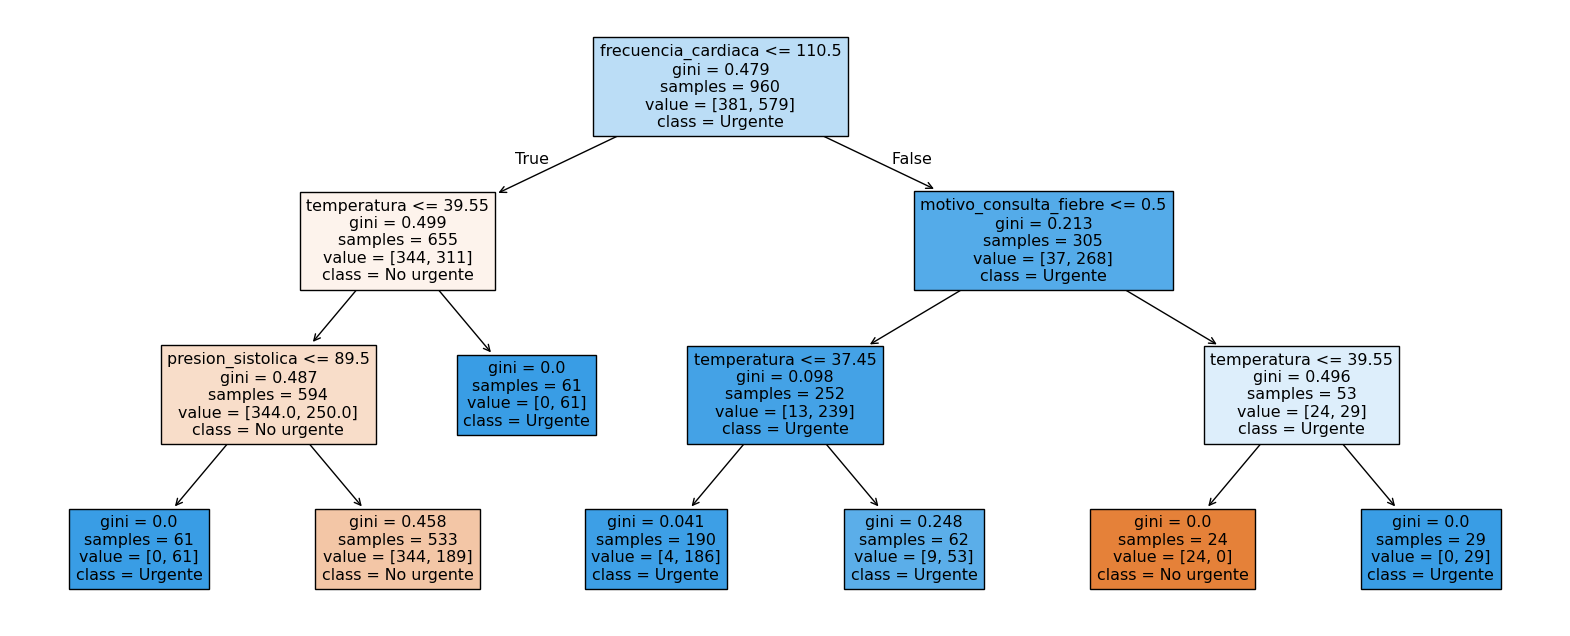

Reglas del árbol:
|--- frecuencia_cardiaca <= 110.50
|   |--- temperatura <= 39.55
|   |   |--- presion_sistolica <= 89.50
|   |   |   |--- class: 1
|   |   |--- presion_sistolica >  89.50
|   |   |   |--- class: 0
|   |--- temperatura >  39.55
|   |   |--- class: 1
|--- frecuencia_cardiaca >  110.50
|   |--- motivo_consulta_fiebre <= 0.50
|   |   |--- temperatura <= 37.45
|   |   |   |--- class: 1
|   |   |--- temperatura >  37.45
|   |   |   |--- class: 1
|   |--- motivo_consulta_fiebre >  0.50
|   |   |--- temperatura <= 39.55
|   |   |   |--- class: 0
|   |   |--- temperatura >  39.55
|   |   |   |--- class: 1

Accuracy entrenamiento: 0.790
Accuracy prueba:        0.796

Reporte de clasificación en prueba:
              precision    recall  f1-score   support

  No urgente       0.67      0.95      0.79        95
     Urgente       0.95      0.70      0.80       145

    accuracy                           0.80       240
   macro avg       0.81      0.82      0.80       240
weighted

In [30]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# TODO 4: entrena arbol_b = DecisionTreeClassifier(max_depth=3, random_state=42) con los datos de entrenamiento
arbol_b = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol_b.fit(X_train_b, y_train_b)

# TODO 5: dibújalo con plot_tree (class_names=['No urgente', 'Urgente']) y muestra sus reglas con export_text
plt.figure(figsize=(20, 8))
plot_tree(arbol_b, filled=True,
          feature_names=list(X_b.columns),
          class_names=['No urgente', 'Urgente'])
plt.show()

print("Reglas del árbol:")
print(export_text(arbol_b, feature_names=list(X_b.columns)))

# TODO 6: muestra el accuracy en entrenamiento y en prueba, y el classification_report en prueba
print(f"Accuracy entrenamiento: {arbol_b.score(X_train_b, y_train_b):.3f}")
print(f"Accuracy prueba:        {arbol_b.score(X_test_b, y_test_b):.3f}")
print("\nReporte de clasificación en prueba:")
y_pred_b = arbol_b.predict(X_test_b)
print(classification_report(y_test_b, y_pred_b, target_names=['No urgente', 'Urgente']))

importancia_b = pd.Series(arbol_b.feature_importances_, index=X_b.columns).sort_values()
print("\nImportancia de variables:")
print(importancia_b.sort_values(ascending=False).round(3))

**Preguntas:**

1. ¿Qué variable eligió el árbol como raíz? ¿Tiene sentido desde el punto de vista clínico? ¿Por qué?
El arbol eligio la frecuencia cardiaca como raiz. Esto tiene mucho sentido a nivel clinico porque el pulso es uno de los signos vitales clave para determinar rapidamente si el estado general de salud de un paciente es critico o estable.

2. Escribe con tus palabras una regla completa (raíz → hoja) que termine en *Urgente*.
Si la frecuencia cardiaca es menor o igual que 110.5 pulsaciones, la temperatura corporal es mayor a 39.55 grados y no se dan otros motivos especificos, el paciente es clasificado como Urgente.

3. ¿Qué variables tienen importancia 0 en este árbol (feature_importances_)? ¿Significa que no sirven para el triaje?
Variables como la edad y los motivos de consulta por dolor de pecho, cefalea o trauma tienen importancia cero en este modelo. Esto no significa que no sean utiles en emergencias medicas reales, sino que para este arbol con profundidad tres no fueron necesarias para clasificar correctamente los casos.

## Bloque B3 · Sobreajuste y `GridSearchCV` con `scoring='recall'`


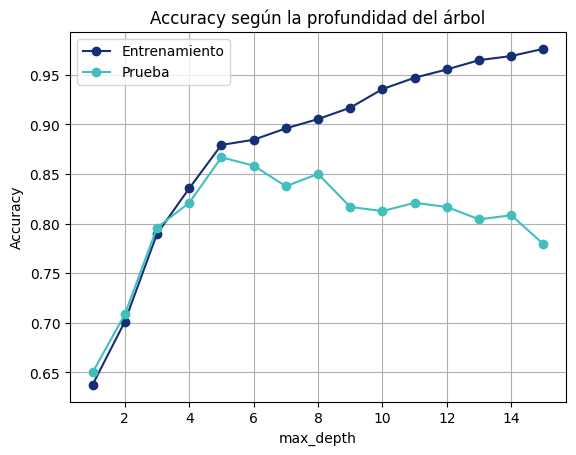

,Entrenamiento,Prueba
max_depth,,
1,0.638,0.650
2,0.701,0.708
3,0.790,0.796
4,0.835,0.821
5,0.879,0.867
6,0.884,0.858
7,0.896,0.838
8,0.905,0.850


Mejores hiperparámetros: {'max_depth': None, 'min_samples_leaf': 10}
Mejor Recall promedio en CV: 0.848


,Modelo,Accuracy,Recall,F1
0,max_depth=3,0.796,0.697,0.805
1,GridSearchCV,0.825,0.841,0.853


In [25]:
from sklearn.metrics import recall_score

# TODO 7: arma la curva de accuracy (entrenamiento y prueba) para max_depth de 1 a 15,
#         igual que en el Bloque A6, y grafícala
filas=[]
for d in range(1, 16):
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train_b, y_train_b)
    filas.append({'max_depth': d,
                  'Entrenamiento': m.score(X_train_b, y_train_b),
                  'Prueba': m.score(X_test_b, y_test_b)})
curva_b = pd.DataFrame(filas).set_index('max_depth')
ax = curva_b.plot(marker='o', color=['#152F75', '#41BFBC'], grid=True)
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy según la profundidad del árbol')
plt.show()

display(curva_b.round(3).head(8))

# TODO 8: crea grid_b con el MISMO param_grid de la Parte A, cv=5 y scoring='recall'.
#         Entrénalo con X_train_b y muestra best_params_ y best_score_
grid_b = GridSearchCV(base, param_grid, cv=5, scoring='recall')
grid_b.fit(X_train_b, y_train_b)
print("Mejores hiperparámetros:", grid_b.best_params_)
print(f"Mejor Recall promedio en CV: {grid_b.best_score_:.3f}")

# TODO 9: compara en X_test_b el arbol_b (max_depth=3) y grid_b con Accuracy, Recall y F1 en una tabla
y_pred_b = arbol_b.predict(X_test_b)
y_pred_grid_b = grid_b.predict(X_test_b)
comparacion_b = pd.DataFrame({
    'Modelo': ['max_depth=3', 'GridSearchCV'],
    'Accuracy': [accuracy_score(y_test_b, y_pred_b), accuracy_score(y_test_b, y_pred_grid_b)],
    'Recall': [recall_score(y_test_b, y_pred_b), recall_score(y_test_b, y_pred_grid_b)],
    'F1': [f1_score(y_test_b, y_pred_b), f1_score(y_test_b, y_pred_grid_b)],
})
display(comparacion_b.round(3))

**Completa la tabla con tus resultados (conjunto de prueba, clase Urgente):**

| Modelo | Hiperparámetros | Accuracy | Recall | F1 |
| --- | --- | --- | --- | --- |
| Árbol inicial | max_depth=3 | 0.796 | 0.697 | 0.805 |
| GridSearchCV | max_depth=None, min_samples_leaf=10 | 0.825 | 0.841 | 0.853 |

**Preguntas:**

1. Según tu curva, ¿a partir de qué profundidad aparece el sobreajuste en el triaje? ¿Cómo lo identificas?
El sobreajuste empieza en la profundidad 5. Se nota porque mientras el acierto en el grupo de entrenamiento sube constantemente hasta 0.97, en el grupo de prueba empieza a caer de forma visible.

2. ¿Cuántos pacientes urgentes (de los que hay en y_test_b) detecta cada modelo? Usa el Recall para calcularlo.
Habia 145 pacientes urgentes en total. El primer arbol detecta 101 pacientes (145 por 0.697) y el arbol optimizado de Grid Search detecta 122 pacientes (145 por 0.841).

3. ¿Por qué en crédito usamos scoring='f1' y en triaje scoring='recall'? ¿Qué error es más grave en cada caso?
En credito se busca un equilibrio general para no perder buenos clientes ni prestar a clientes riesgosos, por eso se usa F1. En cambio, en emergencias de un hospital, mandar a casa por error a alguien con una urgencia real (falso negativo) es gravisimo y pone en riesgo vidas humanas, por eso se prioriza Recall para detectar a la mayor cantidad posible de pacientes criticos.

# Bloque C — Entrenamiento Final, Exportación y Uso con Datos Nuevos



**Idea central:** el split 80/20 sirvió para **elegir** los hiperparámetros (con validación cruzada) y
para **medir** el modelo elegido (con `X_test`). Una vez decidido, el modelo final se entrena con el
**100% de los datos** de crédito: más datos ayudan al modelo que se va a usar en producción.


## C.1 · Reentrenar con el 100% de los datos



* **Modelo de evaluación (80%):** `grid`; sirvió para elegir y medir.
* **Modelo final (100%):** se entrena con `X`, `y` completos usando los valores de `grid.best_params_`.


In [26]:
print(grid.best_params_)   # {'max_depth': 5, 'min_samples_leaf': 10}

arbol_final = DecisionTreeClassifier(max_depth=5,
                                     min_samples_leaf=10,
                                     random_state=42)
arbol_final.fit(X, y)   # X, y completos (900 filas), no X_train
print("arbol_final entrenado con", len(X), "solicitudes.")


{'max_depth': 5, 'min_samples_leaf': 10}
arbol_final entrenado con 900 solicitudes.


In [27]:
# Primeros dos niveles del árbol final (max_depth=1 solo limita lo que se imprime)
print(export_text(arbol_final, feature_names=list(X.columns), max_depth=1))


|--- deuda_actual <= 8014.00
|   |--- ingresos_mensuales <= 2002.00
|   |   |--- truncated branch of depth 4
|   |--- ingresos_mensuales >  2002.00
|   |   |--- truncated branch of depth 4
|--- deuda_actual >  8014.00
|   |--- ingresos_mensuales <= 3850.00
|   |   |--- truncated branch of depth 4
|   |--- ingresos_mensuales >  3850.00
|   |   |--- truncated branch of depth 4



**Observa:** con el 100% de los datos la raíz pasa a ser `deuda_actual <= 8014` (con el 80% era `<= 5975.5`).
Pequeños cambios en los datos producen un árbol distinto: es la **inestabilidad** de los árboles de decisión.
Por eso del Bloque A8 se copian los **hiperparámetros** (`max_depth=5`, `min_samples_leaf=10`), no el árbol.


## C.2 · Exportar el modelo con `joblib`



`joblib` guarda el árbol entrenado (sus preguntas, umbrales y hojas) en un archivo `.pkl`.
A diferencia de SVM, **no hay escalador que guardar**: el árbol trabaja con los datos crudos.


In [28]:
import joblib

joblib.dump(arbol_final, 'modelo_riesgo_arbol.pkl')
print("Modelo exportado a modelo_riesgo_arbol.pkl")


Modelo exportado a modelo_riesgo_arbol.pkl


## C.3 · Usar el modelo con datos nuevos



Así se usaría el archivo **desde otro programa** (por ejemplo, una API): solo se necesita el `.pkl` y
tener instalados `pandas`, `scikit-learn` y `joblib`. El DataFrame lleva las **mismas 5 columnas** de `X`,
con los mismos nombres.


In [29]:
import joblib
import pandas as pd

modelo = joblib.load('modelo_riesgo_arbol.pkl')

solicitudes_nuevas = pd.DataFrame({
    'edad': [35, 28, 50],
    'ingresos_mensuales': [3800, 1200, 2500],
    'meses_empleo': [60, 18, 120],
    'deuda_actual': [2500, 4000, 9000],
    'num_creditos_previos': [2, 1, 4],
})

prediccion = modelo.predict(solicitudes_nuevas)
prob_riesgo = modelo.predict_proba(solicitudes_nuevas)[:, 1]   # columna 1 = clase Riesgoso

solicitudes_nuevas['prediccion'] = prediccion
solicitudes_nuevas['prob_riesgo'] = prob_riesgo.round(2)
solicitudes_nuevas['resultado'] = solicitudes_nuevas['prediccion'].map({0: 'NO RIESGOSO', 1: 'RIESGOSO'})
solicitudes_nuevas


,edad,ingresos_mensuales,meses_empleo,deuda_actual,num_creditos_previos,prediccion,prob_riesgo,resultado
0,35,3800,60,2500,2,0,0.01,NO RIESGOSO
1,28,1200,18,4000,1,1,0.86,RIESGOSO
2,50,2500,120,9000,4,1,0.93,RIESGOSO


**Lectura:** `predict_proba()` devuelve la proporción de solicitudes riesgosas en la **hoja** a la que llega
cada caso. El cliente 1 (deuda baja, ingreso alto) queda como no riesgoso; los clientes 2 (ingreso bajo)
y 3 (deuda alta) quedan como riesgosos.


## Conclusiones



* Un árbol de decisión clasifica con preguntas Sí/No; CART elige en cada nodo la división con **mayor reducción de Gini**.
* El árbol **no necesita escalado**, pero sí variables numéricas (las de texto se codifican).
* Sin límite, el árbol **sobreajusta**: 100% en entrenamiento y peor en prueba. Se controla con `max_depth` y `min_samples_leaf`.
* `plot_tree`, `export_text` y `feature_importances_` hacen al árbol **interpretable**.
* El modelo final se reentrena con el 100% de los datos, se exporta con `joblib` y se usa con datos crudos.
